In [ ]:
# This mounts your Google Drive to the Colab VM.
from google.colab import drive
drive.mount('/content/drive')

# TODO: Enter the foldername in your Drive where you have saved the unzipped
# assignment folder, e.g. 'icv83551/assignments/assignment1/'
FOLDERNAME = 'icv83551/assignments/assignment1/'
assert FOLDERNAME is not None, "[!] Enter the foldername."

# Now that we've mounted your Drive, this ensures that
# the Python interpreter of the Colab VM can load
# python files from within it.
import sys
sys.path.append('/content/drive/My Drive/{}'.format(FOLDERNAME))

# This downloads the CIFAR-10 dataset to your Drive
# if it doesn't already exist.
%cd /content/drive/My\ Drive/$FOLDERNAME/icv83551/datasets/
!bash get_datasets.sh
%cd /content/drive/My\ Drive/$FOLDERNAME

# Image features exercise
*Complete and hand in this completed worksheet (including its outputs and any supporting code outside of the worksheet) with your assignment submission.

We have seen that we can achieve reasonable performance on an image classification task by training a linear classifier on the pixels of the input image. In this exercise we will show that we can improve our classification performance by training linear classifiers not on raw pixels but on features that are computed from the raw pixels.

All of your work for this exercise will be done in this notebook.

In [1]:
import random
import numpy as np
from icv83551.data_utils import load_CIFAR10
import matplotlib.pyplot as plt


%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

#%load_ext autoreload
#%autoreload 2

## Load data
Similar to previous exercises, we will load CIFAR-10 data from disk.

In [2]:
from icv83551.features import color_histogram_hsv, hog_feature

def get_CIFAR10_data(num_training=49000, num_validation=1000, num_test=1000):
    # Load the raw CIFAR-10 data
    cifar10_dir = 'icv83551/datasets/cifar-10-batches-py'

    # Cleaning up variables to prevent loading data multiple times (which may cause memory issue)
    try:
       del X_train, y_train
       del X_test, y_test
       print('Clear previously loaded data.')
    except:
       pass

    X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

    # Subsample the data
    mask = list(range(num_training, num_training + num_validation))
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = list(range(num_training))
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = list(range(num_test))
    X_test = X_test[mask]
    y_test = y_test[mask]

    return X_train, y_train, X_val, y_val, X_test, y_test

X_train, y_train, X_val, y_val, X_test, y_test = get_CIFAR10_data()

## Extract Features
For each image we will compute a Histogram of Oriented
Gradients (HOG) as well as a color histogram using the hue channel in HSV
color space. We form our final feature vector for each image by concatenating
the HOG and color histogram feature vectors.

Roughly speaking, HOG should capture the texture of the image while ignoring
color information, and the color histogram represents the color of the input
image while ignoring texture. As a result, we expect that using both together
ought to work better than using either alone. Verifying this assumption would
be a good thing to try for your own interest.

The `hog_feature` and `color_histogram_hsv` functions both operate on a single
image and return a feature vector for that image. The extract_features
function takes a set of images and a list of feature functions and evaluates
each feature function on each image, storing the results in a matrix where
each column is the concatenation of all feature vectors for a single image.

In [3]:
from icv83551.features import *

# num_color_bins = 10 # Number of bins in the color histogram
num_color_bins = 25 # Number of bins in the color histogram
feature_fns = [hog_feature, lambda img: color_histogram_hsv(img, nbin=num_color_bins)]
X_train_feats = extract_features(X_train, feature_fns, verbose=True)
X_val_feats = extract_features(X_val, feature_fns)
X_test_feats = extract_features(X_test, feature_fns)

# Preprocessing: Subtract the mean feature
mean_feat = np.mean(X_train_feats, axis=0, keepdims=True)
X_train_feats -= mean_feat
X_val_feats -= mean_feat
X_test_feats -= mean_feat

# Preprocessing: Divide by standard deviation. This ensures that each feature
# has roughly the same scale.
std_feat = np.std(X_train_feats, axis=0, keepdims=True)
X_train_feats /= std_feat
X_val_feats /= std_feat
X_test_feats /= std_feat

# Preprocessing: Add a bias dimension
X_train_feats = np.hstack([X_train_feats, np.ones((X_train_feats.shape[0], 1))])
X_val_feats = np.hstack([X_val_feats, np.ones((X_val_feats.shape[0], 1))])
X_test_feats = np.hstack([X_test_feats, np.ones((X_test_feats.shape[0], 1))])

Done extracting features for 1000 / 49000 images


Done extracting features for 2000 / 49000 images


Done extracting features for 3000 / 49000 images


Done extracting features for 4000 / 49000 images


Done extracting features for 5000 / 49000 images


Done extracting features for 6000 / 49000 images


... (39 outputs left out)

Done extracting features for 46000 / 49000 images


Done extracting features for 47000 / 49000 images


Done extracting features for 48000 / 49000 images


Done extracting features for 49000 / 49000 images


## Train Softmax classifier on features
Using the Softmax code developed earlier in the assignment, train Softmax classifiers on top of the features extracted above; this should achieve better results than training them directly on top of raw pixels.

In [4]:
# Use the validation set to tune the learning rate and regularization strength

from icv83551.classifiers.linear_classifier import Softmax

learning_rates = [1e-7, 1e-6]
regularization_strengths = [5e5, 5e6]

results = {}
best_val = -1
best_softmax = None

################################################################################
# TODO:                                                                        #
# Use the validation set to set the learning rate and regularization strength. #
# This should be identical to the validation that you did for the Softmax; save#
# the best trained classifer in best_softmax. If you carefully tune the model, #
# you should be able to get accuracy of above 0.42 on the validation set.      #
################################################################################
# A wider search showed that on the normalized features a much larger learning
# rate and a much smaller regularization work better than the values above
# (those reach only about 0.42), so we search around these values instead.
learning_rates = [1e-3, 1e-2, 3e-2, 1e-1]
regularization_strengths = [1e-4, 1e-3, 1e-2]

for lr in learning_rates:
    for reg in regularization_strengths:
        softmax = Softmax()
        softmax.train(X_train_feats, y_train, learning_rate=lr, reg=reg, num_iters=3000)
        train_accuracy = np.mean(softmax.predict(X_train_feats) == y_train)
        val_accuracy = np.mean(softmax.predict(X_val_feats) == y_val)
        results[(lr, reg)] = (train_accuracy, val_accuracy)
        if val_accuracy > best_val:
            best_val = val_accuracy
            best_softmax = softmax

# Print out results.
for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]
    print('lr %e reg %e train accuracy: %f val accuracy: %f' % (
                lr, reg, train_accuracy, val_accuracy))

print('best validation accuracy achieved: %f' % best_val)

lr 1.000000e-03 reg 1.000000e-04 train accuracy: 0.471612 val accuracy: 0.479000
lr 1.000000e-03 reg 1.000000e-03 train accuracy: 0.471612 val accuracy: 0.478000
lr 1.000000e-03 reg 1.000000e-02 train accuracy: 0.470939 val accuracy: 0.480000
lr 1.000000e-02 reg 1.000000e-04 train accuracy: 0.521694 val accuracy: 0.512000
lr 1.000000e-02 reg 1.000000e-03 train accuracy: 0.522061 val accuracy: 0.513000
lr 1.000000e-02 reg 1.000000e-02 train accuracy: 0.518490 val accuracy: 0.508000
lr 3.000000e-02 reg 1.000000e-04 train accuracy: 0.526469 val accuracy: 0.522000
lr 3.000000e-02 reg 1.000000e-03 train accuracy: 0.524673 val accuracy: 0.520000
lr 3.000000e-02 reg 1.000000e-02 train accuracy: 0.520490 val accuracy: 0.517000
lr 1.000000e-01 reg 1.000000e-04 train accuracy: 0.520000 val accuracy: 0.518000
lr 1.000000e-01 reg 1.000000e-03 train accuracy: 0.524878 val accuracy: 0.511000
lr 1.000000e-01 reg 1.000000e-02 train accuracy: 0.515020 val accuracy: 0.511000
best validation accuracy ach

In [5]:
# Evaluate your trained Softmax on the test set: you should be able to get at least 0.42
y_test_pred = best_softmax.predict(X_test_feats)
test_accuracy = np.mean(y_test == y_test_pred)
print(test_accuracy)

0.508


In [6]:
# Save best softmax model
best_softmax.save("best_softmax_features.npy")

best_softmax_features.npy saved.


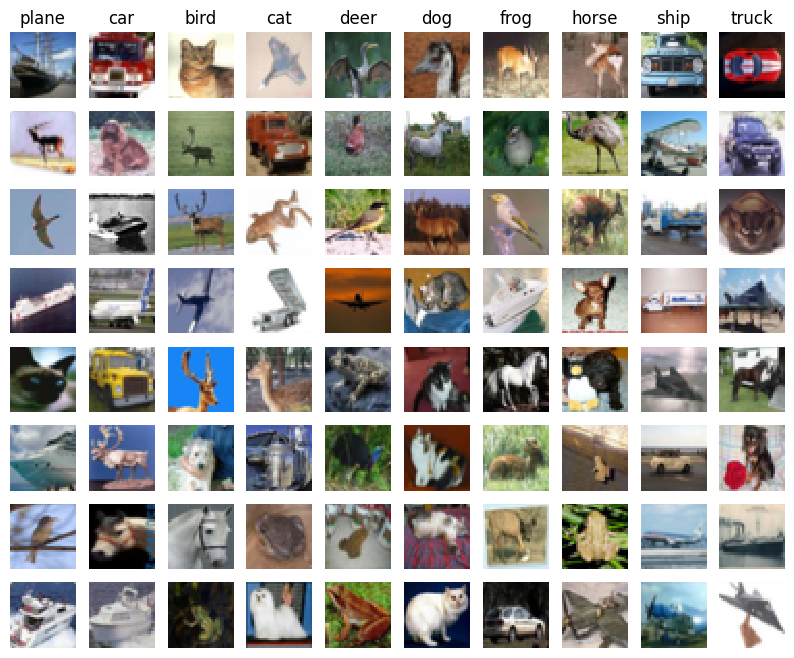

In [7]:
# An important way to gain intuition about how an algorithm works is to
# visualize the mistakes that it makes. In this visualization, we show examples
# of images that are misclassified by our current system. The first column
# shows images that our system labeled as "plane" but whose true label is
# something other than "plane".

examples_per_class = 8
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
for cls, cls_name in enumerate(classes):
    idxs = np.where((y_test != cls) & (y_test_pred == cls))[0]
    idxs = np.random.choice(idxs, examples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt.subplot(examples_per_class, len(classes), i * len(classes) + cls + 1)
        plt.imshow(X_test[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls_name)
plt.show()

### Inline question 1:
Describe the misclassification results that you see. Do they make sense?


$\color{blue}{\textit Your Answer:}$ Most of the mistakes make sense. The classifier mostly mixes up classes that look alike:

- **Vehicles with vehicles:** the "plane" column has ships and boats, the "ship" column has planes and trucks, the "truck" column has cars and planes, and the "car" column has trucks and boats.
- **Animals with animals:** the "dog" column is mostly cats and horses, the "cat" column has a dog and a deer, and the "horse" column has deer.
- **Background and colors:** many images on a blue or white background (sky or water) are labeled "plane" or "ship" (for example birds in the sky labeled as "plane"), and many images on a green or brown background (grass or ground) are labeled as animals like "deer" or "frog".

This makes sense because our features only describe the colors (color histogram) and the general edges and shapes (HOG) of the whole image, not what the object really is. Two images with similar colors and a similar outline get similar features, even if the objects are different. Some mistakes don't make much sense (for example a truck labeled as "cat" or a deer labeled as "car"), and they probably come from unusual colors or backgrounds in the image.





## Neural Network on image features
Earlier in this assigment we saw that training a two-layer neural network on raw pixels achieved better classification performance than linear classifiers on raw pixels. In this notebook we have seen that linear classifiers on image features outperform linear classifiers on raw pixels.

For completeness, we should also try training a neural network on image features. This approach should outperform all previous approaches: you should easily be able to achieve over 55% classification accuracy on the test set; our best model achieves about 60% classification accuracy.

In [8]:
# Preprocessing: Remove the bias dimension
# Make sure to run this cell only ONCE
print(X_train_feats.shape)
X_train_feats = X_train_feats[:, :-1]
X_val_feats = X_val_feats[:, :-1]
X_test_feats = X_test_feats[:, :-1]

print(X_train_feats.shape)

(49000, 170)
(49000, 169)


In [9]:
from icv83551.classifiers.fc_net import TwoLayerNet
from icv83551.solver import Solver

input_dim = X_train_feats.shape[1]
hidden_dim = 500
num_classes = 10

data = {
    'X_train': X_train_feats,
    'y_train': y_train,
    'X_val': X_val_feats,
    'y_val': y_val,
    'X_test': X_test_feats,
    'y_test': y_test,
}

net = TwoLayerNet(input_dim, hidden_dim, num_classes)
best_net = None

################################################################################
# TODO: Train a two-layer neural network on image features. You may want to    #
# cross-validate various parameters as in previous sections. Store your best   #
# model in the best_net variable.                                              #
################################################################################
best_val = -1
for lr in [0.1, 0.3, 1.0]:
    for reg in [1e-4, 1e-3, 1e-2]:
        net = TwoLayerNet(input_dim, hidden_dim, num_classes, reg=reg)
        solver = Solver(net, data,
                        update_rule='sgd',
                        optim_config={'learning_rate': lr},
                        lr_decay=0.95,
                        num_epochs=15, batch_size=200,
                        verbose=False)
        solver.train()
        print('lr %e reg %e train accuracy: %f val accuracy: %f' % (
            lr, reg, solver.train_acc_history[-1], solver.best_val_acc))
        if solver.best_val_acc > best_val:
            best_val = solver.best_val_acc
            best_net = net

print('best validation accuracy achieved: %f' % best_val)


lr 1.000000e-01 reg 1.000000e-04 train accuracy: 0.635000 val accuracy: 0.593000


lr 1.000000e-01 reg 1.000000e-03 train accuracy: 0.617000 val accuracy: 0.594000


lr 1.000000e-01 reg 1.000000e-02 train accuracy: 0.587000 val accuracy: 0.548000


lr 3.000000e-01 reg 1.000000e-04 train accuracy: 0.794000 val accuracy: 0.604000


lr 3.000000e-01 reg 1.000000e-03 train accuracy: 0.746000 val accuracy: 0.608000


lr 3.000000e-01 reg 1.000000e-02 train accuracy: 0.586000 val accuracy: 0.572000


lr 1.000000e+00 reg 1.000000e-04 train accuracy: 0.909000 val accuracy: 0.590000


lr 1.000000e+00 reg 1.000000e-03 train accuracy: 0.828000 val accuracy: 0.592000


lr 1.000000e+00 reg 1.000000e-02 train accuracy: 0.590000 val accuracy: 0.566000
best validation accuracy achieved: 0.608000


In [10]:
# Run your best neural net classifier on the test set. You should be able
# to get more than 58% accuracy. It is also possible to get >60% accuracy
# with careful tuning.

y_test_pred = np.argmax(best_net.loss(data['X_test']), axis=1)
test_acc = (y_test_pred == data['y_test']).mean()
print(test_acc)

0.598


In [11]:
# Save best model
best_net.save("best_two_layer_net_features.npy")

best_two_layer_net_features.npy saved.
